# Feature Engineering - IT24102042

In [17]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, MinMaxScaler
from sklearn.feature_selection import SelectKBest, chi2

In [18]:
# Load dataset
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
!ls /content/drive/

MyDrive


In [4]:
file_path = "/content/drive/MyDrive/2025-Y2-S1-MLB-B8G1-03/results/outputs/student_depression_after_normalization.csv"
df = pd.read_csv(file_path)

In [5]:
#display first five rows
df.head()

,Age,CGPA,Suicidal_Thoughts,Study_Hours,Family_History,Depression,Gender_Male,Gender_Female,Diet_Healthy,Diet_Moderate,Diet_Unhealthy
0,0.60,0.792757,1.0,0.250000,0.0,1.0,1.0,0.0,1.0,0.0,0.0
1,0.24,0.175050,0.0,0.250000,1.0,0.0,0.0,1.0,0.0,1.0,0.0
2,0.52,0.402414,0.0,0.750000,1.0,0.0,1.0,0.0,1.0,0.0,0.0
3,0.40,0.112676,1.0,0.333333,1.0,1.0,0.0,1.0,0.0,1.0,0.0
4,0.28,0.623742,1.0,0.083333,0.0,0.0,0.0,1.0,0.0,1.0,0.0


In [6]:
# Separate features and target
X = df.drop("Depression", axis=1)   # Features
y = df["Depression"]                # Target

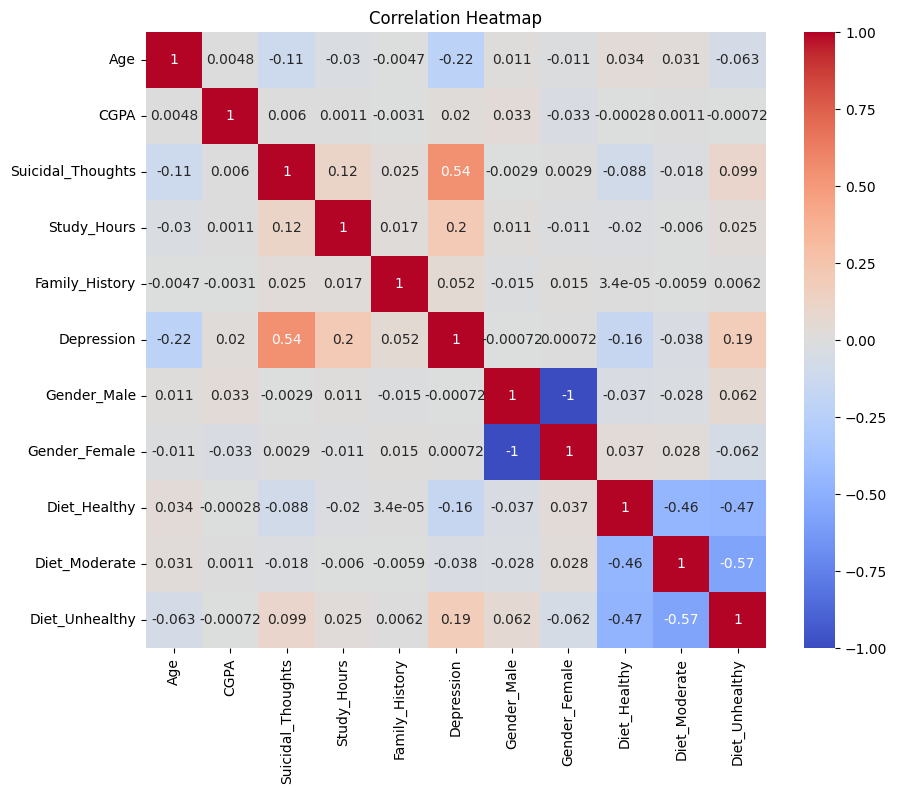

Saved and displayed: /content/drive/MyDrive/2025-Y2-S1-MLB-B8G1-03/results/eda_visualizations/IT24102042_Feature_Engineering_correlation_heatmap.png


In [7]:
#Correlation Heatmap
plt.figure(figsize=(10,8))
# Drop non-numeric columns before calculating correlation
df_numeric = df
sns.heatmap(df_numeric.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
# Save path
save_path = "/content/drive/MyDrive/2025-Y2-S1-MLB-B8G1-03/results/eda_visualizations/IT24102042_Feature_Engineering_correlation_heatmap.png"

# Save and show
plt.savefig(save_path, bbox_inches="tight")
plt.show()

print(f"Saved and displayed: {save_path}")

In [8]:
# Apply Chi-Square test
selector = SelectKBest(score_func=chi2, k=5)  # Keep top 5 features

X_new = selector.fit_transform(abs(X), y)

# Show selected feature names
selected_features = X.columns[selector.get_support()]
print("Selected Features:", selected_features)
df.head()

Selected Features: Index(['Age', 'Suicidal_Thoughts', 'Study_Hours', 'Diet_Healthy',
       'Diet_Unhealthy'],
      dtype='object')


,Age,CGPA,Suicidal_Thoughts,Study_Hours,Family_History,Depression,Gender_Male,Gender_Female,Diet_Healthy,Diet_Moderate,Diet_Unhealthy
0,0.60,0.792757,1.0,0.250000,0.0,1.0,1.0,0.0,1.0,0.0,0.0
1,0.24,0.175050,0.0,0.250000,1.0,0.0,0.0,1.0,0.0,1.0,0.0
2,0.52,0.402414,0.0,0.750000,1.0,0.0,1.0,0.0,1.0,0.0,0.0
3,0.40,0.112676,1.0,0.333333,1.0,1.0,0.0,1.0,0.0,1.0,0.0
4,0.28,0.623742,1.0,0.083333,0.0,0.0,0.0,1.0,0.0,1.0,0.0


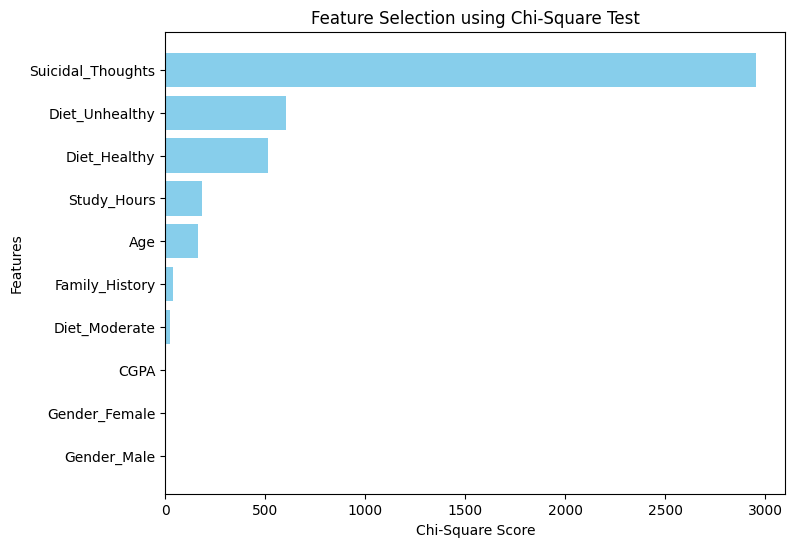

Saved and displayed: /content/drive/MyDrive/2025-Y2-S1-MLB-B8G1-03/results/eda_visualizations/Feature_Engineering_chi_square_feature_selection.png


In [9]:
#visualization for chi-square test
scores = selector.scores_
feature_scores = pd.DataFrame({"Feature": X.columns, "Chi2 Score": scores})
feature_scores = feature_scores.sort_values(by="Chi2 Score", ascending=False)

plt.figure(figsize=(8,6))
plt.barh(feature_scores["Feature"], feature_scores["Chi2 Score"], color="skyblue")
plt.xlabel("Chi-Square Score")
plt.ylabel("Features")
plt.title("Feature Selection using Chi-Square Test")
plt.gca().invert_yaxis()  # highest score at top

# Save path
save_path = "/content/drive/MyDrive/2025-Y2-S1-MLB-B8G1-03/results/eda_visualizations/Feature_Engineering_chi_square_feature_selection.png"

# Save and show
plt.savefig(save_path, bbox_inches="tight")
plt.show()

print(f"Saved and displayed: {save_path}")

In [10]:
from sklearn.ensemble import RandomForestClassifier

X = df.drop("Depression", axis=1)
y = df["Depression"]

model = RandomForestClassifier(random_state=42)
model.fit(X, y)

importances = model.feature_importances_
features = X.columns

# Show ranked features
feature_importance = pd.DataFrame({"Feature": features, "Importance": importances})
feature_importance = feature_importance.sort_values(by="Importance", ascending=False)

print("Feature Importance Ranking:")
print(feature_importance)

top5_features = feature_importance["Feature"].head(5).tolist()

Feature Importance Ranking:
             Feature  Importance
1               CGPA    0.376645
2  Suicidal_Thoughts    0.270625
0                Age    0.161775
3        Study_Hours    0.129241
9     Diet_Unhealthy    0.018923
4     Family_History    0.015255
7       Diet_Healthy    0.010082
6      Gender_Female    0.006302
5        Gender_Male    0.006290
8      Diet_Moderate    0.004862


/tmp/ipython-input-3142795110.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feature_importance["Importance"], y=feature_importance["Feature"], palette="viridis")


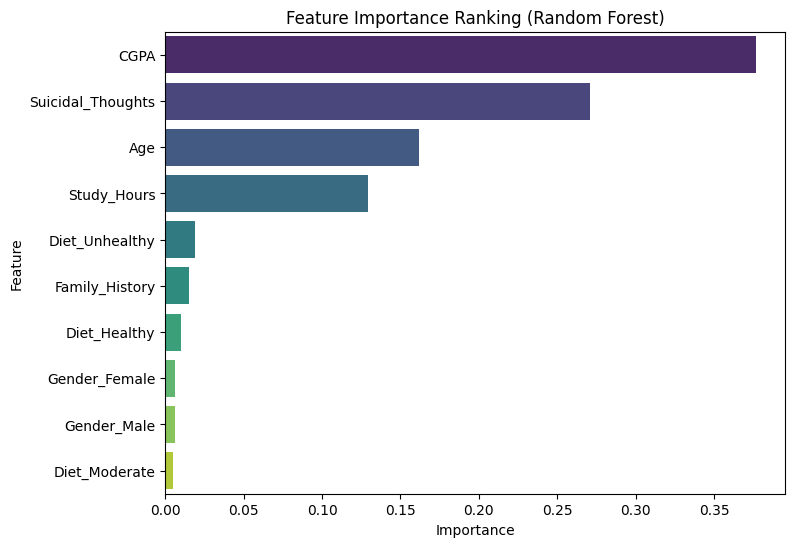

Saved and displayed: /content/drive/MyDrive/2025-Y2-S1-MLB-B8G1-03/results/eda_visualizations/Feature_Engineering_random_forest_feature_importance.png


In [11]:
plt.figure(figsize=(8,6))
sns.barplot(x=feature_importance["Importance"], y=feature_importance["Feature"], palette="viridis")
plt.title("Feature Importance Ranking (Random Forest)")

# Save path
save_path = "/content/drive/MyDrive/2025-Y2-S1-MLB-B8G1-03/results/eda_visualizations/Feature_Engineering_random_forest_feature_importance.png"

# Save and show
plt.savefig(save_path, bbox_inches="tight")
plt.show()

print(f"Saved and displayed: {save_path}")

In [14]:
print("Selected Features:", selected_features.tolist())

Selected Features: ['Age', 'Suicidal_Thoughts', 'Study_Hours', 'Diet_Healthy', 'Diet_Unhealthy']


In [15]:
#Summary Table
summary = pd.DataFrame({
    "Feature": X.columns,
    "Chi2 Score": selector.scores_,
    "RandomForest Importance": importances
}).sort_values(by="RandomForest Importance", ascending=False)

print(summary)

             Feature   Chi2 Score  RandomForest Importance
1               CGPA     1.739566                 0.376645
2  Suicidal_Thoughts  2951.849506                 0.270625
0                Age   165.446961                 0.161775
3        Study_Hours   183.065032                 0.129241
9     Diet_Unhealthy   603.257662                 0.018923
4     Family_History    38.574009                 0.015255
7       Diet_Healthy   511.152134                 0.010082
6      Gender_Female     0.007755                 0.006302
5        Gender_Male     0.006199                 0.006290
8      Diet_Moderate    25.514552                 0.004862


In [16]:
# Keep only selected features + target column
final_df = df[top5_features + ["Depression"]]
print("\nFinal Dataset with Top 5 Features:")
print(final_df.head())

# Save for next step
save_path = "/content/drive/MyDrive/2025-Y2-S1-MLB-B8G1-03/results/outputs/student_depression_After_Feature_Engineering.csv"
final_df.to_csv(save_path, index=False)

print(f"Final dataset saved at: {save_path}")
print("Final Shape:", final_df.shape)


Final Dataset with Top 5 Features:
       CGPA  Suicidal_Thoughts   Age  Study_Hours  Diet_Unhealthy  Depression
0  0.792757                1.0  0.60     0.250000             0.0         1.0
1  0.175050                0.0  0.24     0.250000             0.0         0.0
2  0.402414                0.0  0.52     0.750000             0.0         0.0
3  0.112676                1.0  0.40     0.333333             0.0         1.0
4  0.623742                1.0  0.28     0.083333             0.0         0.0
Final dataset saved at: /content/drive/MyDrive/2025-Y2-S1-MLB-B8G1-03/results/outputs/student_depression_After_Feature_Engineering.csv
Final Shape: (27265, 6)
